# **Improving Reasoning with Inference-Time Scaling**

In [1]:
import os
import sys


os.environ["PYTHONUTF8"] = "1"
print(os.environ.get("PYTHONUTF8"))

1


In [2]:
import torch
from ipynb.fs.full.generating_text_qwen_3 import get_device
from pathlib import Path
from reasoning_from_scratch.qwen3 import (
    download_qwen3_small,
    Qwen3Tokenizer,
    Qwen3Model,
    QWEN_CONFIG_06_B
)




device = get_device()


Tokenizer is Already downloaded at path:  qwen3\tokenizer-base.json
Model is Already downloaded at path: qwen3\qwen3-0.6B-base.pth
Total time taken to download QWEN-3(small 0.6B): 0.0
 in the middle of the in the middle of the

Time: 9.06 sec
0 tokens/sec
 in the middle of the

Time: 7.21 sec
0 tokens/sec


## **Loading the Model and Tokenizer**

In [3]:
def load_model_and_tokenizer(
    which_model, device, use_compile, local_dir="qwen3"
):
    if which_model == "base":

        download_qwen3_small(
            kind="base", tokenizer_only=False, out_dir=local_dir
        )

        tokenizer_path = Path(local_dir) / "tokenizer-base.json"
        model_path = Path(local_dir) / "qwen3-0.6B-base.pth"
        tokenizer = Qwen3Tokenizer(tokenizer_file_path=tokenizer_path)

    elif which_model == "reasoning":

        download_qwen3_small(
            kind="reasoning", tokenizer_only=False, out_dir=local_dir
        )

        tokenizer_path = Path(local_dir) / "tokenizer-reasoning.json"
        model_path = Path(local_dir) / "qwen3-0.6B-reasoning.pth"
        tokenizer = Qwen3Tokenizer(
            tokenizer_file_path=tokenizer_path,
            apply_chat_template=True,
            add_generation_prompt=True,
            add_thinking=True,
        )

    else:
        raise ValueError(f"Invalid choice: which_model={which_model}")

    model = Qwen3Model(QWEN_CONFIG_06_B)
    model.load_state_dict(torch.load(model_path))

    model.to(device)

    if use_compile:
        torch._dynamo.config.allow_unspec_int_on_nn_module = True
        model = torch.compile(model)

    return model, tokenizer

In [4]:
from ipynb.fs.defs.evaluating_model_math import generate_text_basic_stream_cache, render_prompt

print("Printing the Deivce: ", device)

model, tokenizer = load_model_and_tokenizer(
    which_model = "base",
    device=device,
    use_compile = False
)



raw_prompt = (
    "Half the value of $3x-9$ is $x+37$. "
    "What is the value of $x$?"
)

prompt = render_prompt(raw_prompt)

print(prompt)


Printing the Deivce:  cpu
✓ qwen3\qwen3-0.6B-base.pth already up-to-date
You are a helpful math assistant.
Answer the question and write the final result on a new line as:
\boxed{ANSWER}

Question:
Half the value of $3x-9$ is $x+37$. What is the value of $x$?

Answer:


In [5]:
def generate_text_stream_concat_flex(
    model, tokenizer, prompt, device, max_new_tokens,
    verbose=False, 
    generate_func=None,  # New
    **generate_kwargs  # New
):

    if generate_func is None:  # New
        generate_func = generate_text_basic_stream_cache
        
    input_ids = torch.tensor(
        tokenizer.encode(prompt), device=device
        ).unsqueeze(0)

    generated_ids = []
    for token in generate_func(  # New
        model=model,
        token_ids=input_ids,
        max_new_tokens=max_new_tokens,
        eos_token_id=tokenizer.eos_token_id,
        **generate_kwargs,  # New
    ):
        next_token_id = token.squeeze(0)
        generated_ids.append(next_token_id.item())

        if verbose:
            print(
                tokenizer.decode(next_token_id.tolist()),
                end="",
                flush=True
            )
    return tokenizer.decode(generated_ids)

In [6]:
response = generate_text_stream_concat_flex(
    model, tokenizer, prompt, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_basic_stream_cache  # NEW
)

 \boxed{20}

**`Note:`** The correct answer is 83 but model gave the answer 20, which is wrong

## **1- Inference Time Scaling Method - Chain of Thought Prompting**

Let's try to improve the model on reasoning task. For this we are first using the chain of thought reasoning. A classic way to improve model performance is to modify the prompt to encourage the model to think or explain step by step

In [7]:
prompt_cot = prompt + " \n\nExplain step by step."

response_cot = generate_text_stream_concat_flex(
    model, tokenizer, prompt_cot, device,
    max_new_tokens=2048, verbose=True,
)

 To solve the problem, we need to find the value of \( x \) such that half the value of \( 3x - 9 \) is equal to \( x + 37 \).

### Step 1: Set up the equation
We are given that half the value of \( 3x - 9 \) is equal to \( x + 37 \). This can be written as:
\[
\frac{1}{2}(3x - 9) = x + 37
\]

### Step 2: Eliminate the fraction
To eliminate the fraction, multiply both sides of the equation by 2:
\[
2 \cdot \frac{1}{2}(3x - 9) = 2(x + 37)
\]
Simplifying both sides:
\[
3x - 9 = 2x + 74
\]

### Step 3: Solve for \( x \)
Subtract \( 2x \) from both sides to isolate \( x \):
\[
3x - 2x - 9 = 74
\]
Simplify:
\[
x - 9 = 74
\]
Add 9 to both sides to solve for \( x \):
\[
x = 74 + 9
\]
\[
x = 83
\]

### Final Answer:
\[
\boxed{83}
\]

### **Controlling output diversity with temperature scaling**

#### **Understanding the process of selecting the next token**

In [8]:
ex_prompt = "The Capital of Germany is"

response = generate_text_stream_concat_flex(
    model, tokenizer, ex_prompt, device, max_new_tokens=5, verbose=True
)

response

 ____
A. Berlin

' ____\nA. Berlin'

In [9]:
# converting the input token into ids
input_token_ids = torch.tensor(
    tokenizer.encode(ex_prompt), device=device
).unsqueeze(0)

print(input_token_ids)

# Get scores for next token
with torch.inference_mode():
    next_token_logits = model(input_token_ids)[:, -1]
print(next_token_logits.shape) # Shape: [1, vocab_size]

# Find vocabulary index with highest score
max_token_id = torch.argmax(next_token_logits)
print(f"Token ID: {max_token_id}")
print(f"Decoded token: '{tokenizer.decode([max_token_id])}'")

tensor([[  785, 18374,   315,  9856,   374]])
torch.Size([1, 151936])
Token ID: 1304
Decoded token: ' __'


In [10]:
import matplotlib.pyplot as plt

def plot_scores_bar(
    next_token_logits, start=19_800, end=19_900,
    arrow=True, ylabel="Logit value"
):
    # Select vocabulary subsection
    x = torch.arange(start, end)

    # .cpu() is a shortcut for to(torch.device("cpu"))
    logits_section = next_token_logits[0, start:end].float().cpu()
    print(logits_section)

    # Plot logits
    plt.bar(x, logits_section)
    plt.xlabel("Vocabulary index")
    plt.ylabel(ylabel)

    # Highlight max logit
    if arrow:
        max_idx = torch.argmax(logits_section)
        plt.annotate(
            "Berlin",
            xy=(x[max_idx], logits_section[max_idx]),
            xytext=(x[max_idx] - 25, logits_section[max_idx] - 2),
            arrowprops={
                "facecolor": "black", "arrowstyle": "->", "lw": 1.5
            },
            fontsize=10,
        )

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()



tensor([ 8.3125,  6.1562, -0.8789,  0.5469, -1.3438,  4.0000,  8.1875,  4.5312,
        -5.3750,  5.6562,  1.6250, -1.6875,  2.0781,  5.2812,  2.9688, -0.2373,
        -2.0938,  2.7500,  5.5625,  5.8125,  8.3750,  3.1875,  8.7500,  3.3438,
         5.5938, 11.5625,  5.8125,  2.3281,  6.7812,  0.9531, -2.3750, -7.3125,
         2.3438,  9.1875,  2.8594,  2.6875,  7.9688,  9.2500,  6.2188,  2.4688,
         2.0000, -2.9219,  2.5312, -2.8125, -0.4434,  5.2188, 19.1250,  3.2656,
         0.2490,  1.8438,  7.5000, 11.3125, -0.5000,  6.5000,  4.6875, -0.7227,
        -0.6328,  4.3125,  7.0312,  1.0469,  4.9375,  1.6562,  1.2031, -1.4219,
        -4.0312,  0.6758,  2.4844, 10.5000,  8.8750,  6.1562,  5.9375, -0.7695,
        -0.4629,  3.3906,  8.3125,  2.1406, -2.8125,  1.0156, -3.0000,  3.2031,
        -1.0312,  7.2500, -0.5117,  2.9688,  8.1250,  6.6250,  5.5000,  0.0396,
        -1.3047, -2.0625,  4.9062, -2.3438,  4.3750,  1.6953, -2.1562, -0.7305,
         5.3125,  1.6719,  2.2188,  0.43

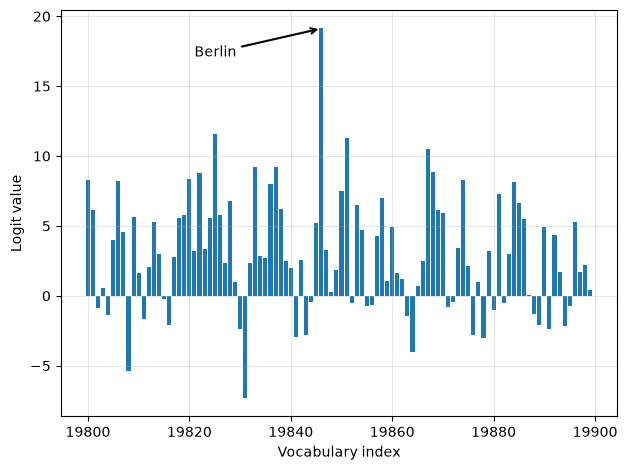

In [11]:
plot_scores_bar(next_token_logits)

#### **Rescaling token scores (logits) via a temperature parameter**

In [12]:
def scale_logits_by_temperature(logits, temperature):
    if temperature <= 0:
        raise ValueError("Temperature must be positive")
    return logits / temperature

In [13]:
def plot_logits_with_temperature(
    next_token_logits, start=19_800, end=19_900,
    temps=(0.5, 5.0),
):
    x = torch.arange(start, end)
    logits_orig = next_token_logits[0, start:end].float().cpu()

    # Apply temperature scaling
    logits_scaled = [
        scale_logits_by_temperature(logits_orig, T) for T in temps
    ]
    # Plot logits
    plt.plot(x, logits_orig, label="Original logits", lw=2)
    plt.plot(
        x, logits_scaled[0],
        label=f"T={temps[0]} (sharper)", ls="--", lw=1
    )
    plt.plot(
        x, logits_scaled[1],
        label=f"T={temps[1]} (flatter)", ls=":", lw=3
    )

    # Highlight max logit
    max_idx = torch.argmax(logits_orig)
    plt.annotate(
        "Berlin",
        xy=(x[max_idx], logits_orig[max_idx]),
        xytext=(x[max_idx] - 25, logits_orig[max_idx] + 2),
        arrowprops={"facecolor": "black", "arrowstyle": "->", "lw": 1.5},
        fontsize=12,
    )
    
    plt.xlabel("Vocabulary index")
    plt.ylabel("Logit value")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()




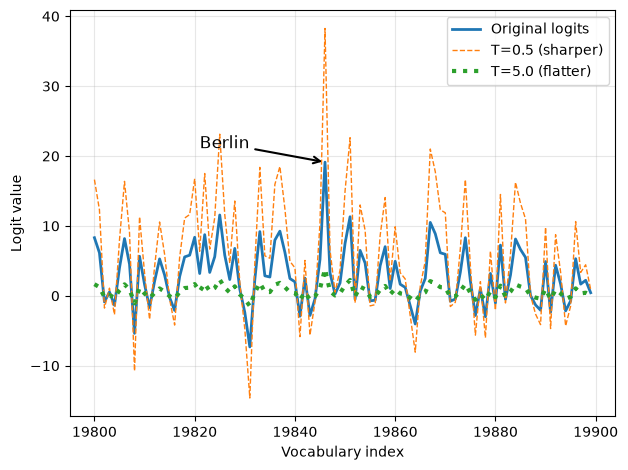

In [14]:
plot_logits_with_temperature(
    next_token_logits,
    temps=(0.5, 5.0)
)

#### **Sampling the next token from a probability distribution**

Probability sum: tensor(1., dtype=torch.bfloat16)
tensor([2.3007e-05, 1.4961e-05, 3.6508e-06, 4.8578e-06, 3.3230e-06, 9.7156e-06,
        2.2531e-05, 1.0788e-05, 1.4827e-06, 1.3530e-05, 6.0201e-06, 3.1143e-06,
        6.6161e-06, 1.2517e-05, 7.8678e-06, 4.1425e-06, 2.8759e-06, 7.5698e-06,
        1.3232e-05, 1.3947e-05, 2.3246e-05, 8.2254e-06, 2.5034e-05, 8.5235e-06,
        1.3292e-05, 4.4107e-05, 1.3947e-05, 6.9439e-06, 1.6928e-05, 5.2750e-06,
        2.7120e-06, 1.0133e-06, 6.9737e-06, 2.7299e-05, 7.6890e-06, 7.4804e-06,
        2.1458e-05, 2.7776e-05, 1.5080e-05, 7.1526e-06, 6.4969e-06, 2.4289e-06,
        7.2420e-06, 2.4885e-06, 3.9935e-06, 1.2398e-05, 2.0027e-04, 8.3447e-06,
        4.5896e-06, 6.3181e-06, 1.9550e-05, 4.1962e-05, 3.9339e-06, 1.5974e-05,
        1.1146e-05, 3.7700e-06, 3.8445e-06, 1.0312e-05, 1.7762e-05, 5.3644e-06,
        1.1683e-05, 6.0797e-06, 5.5432e-06, 3.2783e-06, 1.9521e-06, 4.9770e-06,
        7.1526e-06, 3.5286e-05, 2.5630e-05, 1.4961e-05, 1.4305e-05, 3.

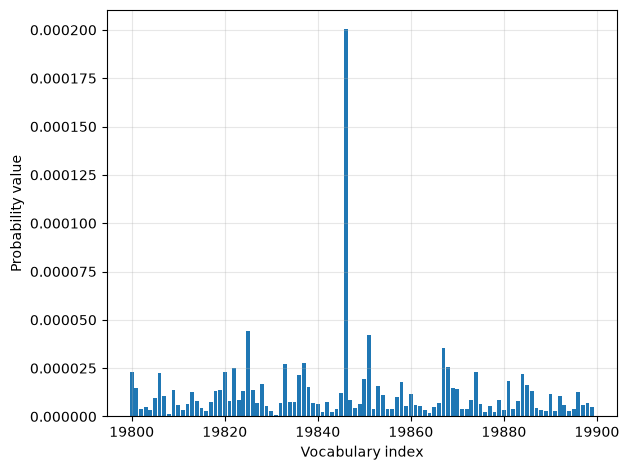

In [15]:
# Rescale next-token scores
rescaled_logits = scale_logits_by_temperature(next_token_logits, 5.0)

# Convert rescaled logits into probability scores
next_token_probas = torch.softmax(
    rescaled_logits, dim=-1
)

print("Probability sum:", torch.sum(next_token_probas))

plot_scores_bar(
    next_token_probas, arrow=False, ylabel="Probability value"
)


In [16]:
print("Token ID 19,846 probability:", next_token_probas[:, 19846])

print("Highest probability:", max(next_token_probas.squeeze(0)))

# Sample token according to probabilities
torch.manual_seed(123)
print(
    "Sampled token:",
    torch.multinomial(next_token_probas.cpu(), num_samples=1)
)

print(tokenizer.decode([65094]))

Token ID 19,846 probability: tensor([0.0002], dtype=torch.bfloat16)
Highest probability: tensor(0.0002, dtype=torch.bfloat16)
Sampled token: tensor([[65094]])
 mistress


In [17]:
def count_samples(probas, num_samples=1000, threshold=1, tokenizer=None):
    # Draw samples according to probabilities
    samples = torch.multinomial(
        probas.cpu(), num_samples=num_samples, replacement=True
    )
    
    # Count how often each index was selected
    counts = torch.bincount(samples.squeeze(0), minlength=1)
    
    # Print results
    for i, c in enumerate(counts):
        if c > threshold:
            if tokenizer is None:
                print(f"Vocab index {i}: {c.item()}x")
            else:
                print(f"'{tokenizer.decode([i])}': {c.item()}x")


In [18]:
torch.manual_seed(123)
count_samples(next_token_probas, tokenizer=tokenizer)

'w': 2x
'"
': 2x
'?
': 2x
' Germany': 2x
' reflected': 2x
' jars': 2x
' parted': 2x
'�': 2x


In [19]:
torch.manual_seed(123)
probas_lowT = torch.softmax(
    scale_logits_by_temperature(next_token_logits, 0.35), dim=-1
)
count_samples(probas_lowT, threshold=1, tokenizer=tokenizer)

':': 8x
'
': 37x
'

': 2x
':
': 9x
' __': 289x
'____': 12x
' called': 5x
'?
': 22x
' Berlin': 141x
' ____': 157x
' ______': 281x
' Munich': 5x
' Hamburg': 6x
' _____': 25x


In [20]:
print(probas_lowT[0, 19_846])
tokenizer.decode([19846])

tensor(0.1079, dtype=torch.bfloat16)


' Berlin'

#### **Adding temperature scaling to the text generation function**

In [21]:
from reasoning_from_scratch.qwen3 import KVCache

@torch.inference_mode()
def generate_text_temp_stream_cache(
    model,
    token_ids,
    max_new_tokens,
    eos_token_id=None,
    temperature=0.
):
    model.eval()
    cache = KVCache(n_layers=model.cfg["n_layers"])
    model.reset_kv_cache()

    # Step 3.1: Get logits
    out = model(token_ids, cache=cache)[:, -1]
    for step in range(max_new_tokens):

        ########################################
        # NEW:
        orig_device = token_ids.device

        if temperature is None or temperature == 0.0:
            next_token = torch.argmax(out, dim=-1, keepdim=True)

        else:
            # Step 3.2: Apply temperature scaling on logits
            logits = scale_logits_by_temperature(out, temperature)

            # Step 3.3: Convert to probabilities
            probas = torch.softmax(logits, dim=-1)

            # Step 3.4: Sample token according to probabilities
            next_token = torch.multinomial(probas.cpu(), num_samples=1)
            next_token = next_token.to(orig_device)

        if (eos_token_id is not None
                and torch.all(next_token == eos_token_id)):
            break

        yield next_token
        if step + 1 < max_new_tokens:  # Skips the forward pass after the last token is generated
            out = model(next_token, cache=cache)[:, -1]

In [22]:
torch.manual_seed(123)
response = generate_text_stream_concat_flex(
    model, tokenizer, prompt, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_temp_stream_cache,
    temperature=1.1
)


 We begin with the equation \(\frac{1}{2}(3x - 9) = x + 37\).
First, distribute the \(\frac{1}{2}\) on the left-side of the equation to get \(3x - 9 = 2(x + 37)\).
Then simplify the right side of the equation by using the distributive property and combining like terms: \(3x - 9 = 2x + 74\).
Next, subtract \(2x\) from both sides of the equation to get \(x - 9 = 2x + 74\).
Next, subtract \(x\) from both sides of the equation to reduce the number of \(x\) terms on the right side to exactly 1: \(-9 = x + 74\).
Finally, subtract 74 from both sides of the equation to get \(x = -83\).
The value of \(x\) is \(\boxed{-83}\).

## **Balancing diversity and coherence with top-p sampling**

#### **Selecting a subset of top-p tokens**

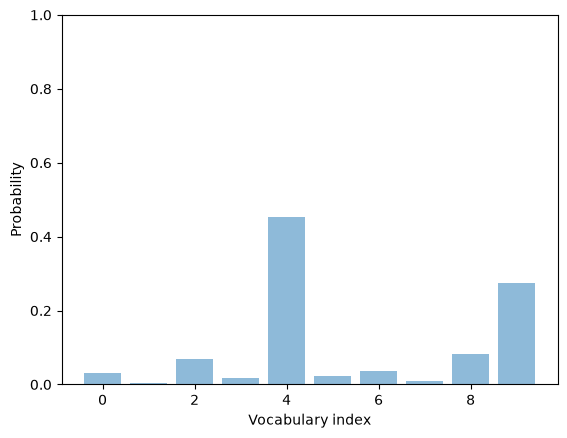

In [23]:
# Step 3.1: Get logits (here: use toy logits for 10 tokens)
toy_logits = torch.tensor(
    [-0.7, -3.0, 0.1, -1.2, 2.0, -1.0, -0.5, -2.0, 0.3, 1.5]
)

# Step 3.2: Apply temperature scaling
toy_logits_scaled = scale_logits_by_temperature(toy_logits, 1.0)

# Step 3.3: Convert to probabilities
toy_probas = torch.softmax(toy_logits_scaled, dim=-1)

plt.bar(
    torch.arange(len(toy_logits_scaled)), toy_probas,
    alpha=0.5
)

plt.ylim([0, 1])
plt.xlabel("Vocabulary index")
plt.ylabel("Probability")
# plt.savefig("12.pdf")
plt.show()

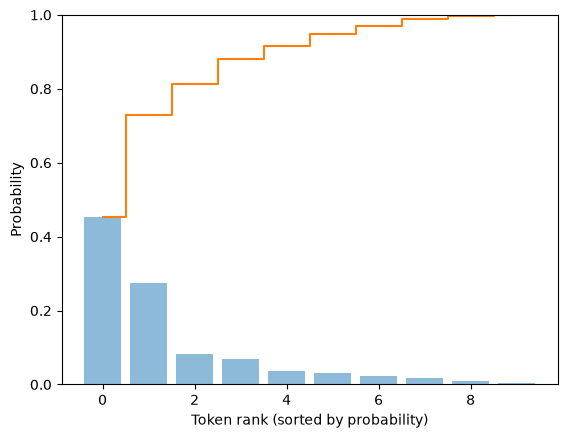

In [24]:
# Step 4.1: Sort by descending probability
sorted_probas, sorted_idx = torch.sort(toy_probas, descending=True)

# Step 4.2: Compute cumulative sum
cumsum = torch.cumsum(sorted_probas, dim=-1)

plt.bar(
    torch.arange(len(sorted_probas)), sorted_probas, 
        alpha=0.5
)
plt.step(
    torch.arange(len(cumsum)), cumsum, 
    where="mid", color="C1", label="Cumulative sum"
)

plt.ylim([0, 1])
plt.xlabel("Token rank (sorted by probability)")
plt.ylabel("Probability")
plt.show()

In [25]:
# Step 4.3.1: Apply top-p threshold (e.g., keep tokens until cumulative mass > 0.8)
top_p = 0.8
keep_mask = cumsum <= top_p
n_kept = torch.sum(keep_mask).item()
print("Cumulative sum:", cumsum)
print("Tokens kept:", n_kept)

Cumulative sum: tensor([0.4538, 0.7290, 0.8119, 0.8798, 0.9170, 0.9475, 0.9701, 0.9886, 0.9969,
        1.0000])
Tokens kept: 2


In [26]:
# A more common variant is to include the token that crosses the threshold
keep_mask = (cumsum - sorted_probas) < top_p
n_kept = keep_mask.sum().item()
print("Tokens kept:", n_kept)

Tokens kept: 3


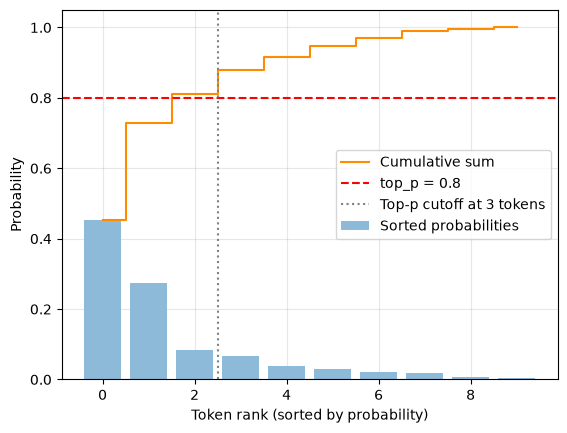

In [27]:
plt.bar(
    torch.arange(len(sorted_probas)), sorted_probas, 
    alpha=0.5, label="Sorted probabilities"
)
plt.step(
    torch.arange(len(cumsum)), cumsum, where="mid",
    color="darkorange", label="Cumulative sum"
)

# Highlight cutoff
plt.axhline(
    top_p, color="red", linestyle="--",
    label=f"top_p = {top_p}"
)
plt.axvline(
    n_kept - 0.5, color="gray", linestyle=":",
    label=f"Top-p cutoff at {n_kept} tokens"
)

plt.xlabel("Token rank (sorted by probability)")
plt.ylabel("Probability")
plt.legend()
plt.grid(alpha=0.3)
plt.ylim(0, 1.05)
# plt.savefig("14.pdf")
plt.show()

In [28]:
# Step 4.3.2: Zero out beyond cutoff
kept_sorted = torch.where(
    keep_mask, sorted_probas,
    torch.zeros_like(sorted_probas)
)

# Step 4.3.3: Map back to original order
filtered = torch.zeros_like(toy_probas).scatter(0, sorted_idx, kept_sorted)

print(filtered)

# Step 4.4: Renormalize to sum to 1
denom = torch.sum(filtered).clamp_min(1e-12)
renormalized = filtered / denom
print(renormalized)

tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.4538, 0.0000, 0.0000, 0.0000, 0.0829,
        0.2752])
tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.5589, 0.0000, 0.0000, 0.0000, 0.1021,
        0.3390])


#### **Adding a top-p filter to the text generation function**

In [29]:
def top_p_filter(probas, top_p):
    if top_p is None or top_p >= 1.0:
        return probas

    # Step 4.1: Sort by descending probability
    sorted_probas, sorted_idx = torch.sort(probas, dim=1, descending=True)

    # Step 4.2: Cumulative sum
    cumprobas = torch.cumsum(sorted_probas, dim=1)

    # Step 4.3.1: Keep tokens where prefix cumulative mass (before token) is < top_p
    # Example: [0.5, 0.41, 0.09] with top_p=0.9 should keep the first two tokens
    prefix = cumprobas - sorted_probas   # cumulative mass before each token
    keep = prefix < top_p
    # Always keep at least one token (fallback for very small/non-positive top_p)
    keep[:, 0] = True    

    # Step 4.3.2: Zero out beyond cutoff
    kept_sorted = torch.where(
        keep, sorted_probas,
        torch.zeros_like(sorted_probas)
    )
    # Step 4.3.3: Map back to original order
    filtered = torch.zeros_like(probas).scatter(1, sorted_idx, kept_sorted)

    # Step 4.4: Renormalize to sum to 1
    denom = torch.sum(filtered, dim=1, keepdim=True).clamp_min(1e-12)
    return filtered / denom

In [30]:
with torch.inference_mode():
    next_token_logits = model(input_token_ids)[:, -1]
print(next_token_logits.shape)

torch.manual_seed(123)
probas_lowT = torch.softmax(
    scale_logits_by_temperature(next_token_logits, 0.35), dim=-1
)
count_samples(probas_lowT, threshold=1, tokenizer=tokenizer)

torch.Size([1, 151936])
':': 8x
'
': 37x
'

': 2x
':
': 9x
' __': 289x
'____': 12x
' called': 5x
'?
': 22x
' Berlin': 141x
' ____': 157x
' ______': 281x
' Munich': 5x
' Hamburg': 6x
' _____': 25x


In [31]:
torch.manual_seed(123)
probas_lowT = torch.softmax(
    scale_logits_by_temperature(next_token_logits, 0.35), dim=-1
)
probas_lowT_filtered = top_p_filter(probas_lowT, top_p=0.8)

count_samples(probas_lowT_filtered, threshold=1, tokenizer=tokenizer)

' __': 334x
' Berlin': 138x
' ____': 197x
' ______': 331x


In [32]:
@torch.inference_mode()
def generate_text_top_p_stream_cache(
    model,
    token_ids,
    max_new_tokens,
    eos_token_id=None,
    temperature=0.,
    top_p=None
):
    model.eval()
    cache = KVCache(n_layers=model.cfg["n_layers"])
    model.reset_kv_cache()

    # Step 3.1: Get logits
    out = model(token_ids, cache=cache)[:, -1]
    for step in range(max_new_tokens):

        orig_device = token_ids.device

        if temperature is None or temperature == 0.0:
            next_token = torch.argmax(out, dim=-1, keepdim=True)

        else:
            # Step 3.2: Apply temperature scaling on logits
            logits = scale_logits_by_temperature(out, temperature)

            # Step 3.3: Convert to probabilities
            probas = torch.softmax(logits, dim=-1)

            # (New) Step 4: Apply top-p filter to probabilities
            probas = top_p_filter(probas, top_p)  

            
            # Step 3.4: Sample token according to probabilities
            next_token = torch.multinomial(probas.cpu(), num_samples=1)
            next_token = next_token.to(orig_device)

        if (eos_token_id is not None
                and torch.all(next_token == eos_token_id)):
            break

        yield next_token
        if step + 1 < max_new_tokens:  # Skips the forward pass after the last token is generated
            out = model(next_token, cache=cache)[:, -1]     

In [33]:
torch.manual_seed(123)
response = generate_text_stream_concat_flex(
    model, tokenizer, prompt, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_top_p_stream_cache,
    temperature=0.5,
    top_p=0.8, 
)

 \boxed{18}

## **Improving response accuracy with self-consistency**

Generate multiple answers via sampling and vote

In [34]:
from reasoning_from_scratch.ch03 import extract_final_candidate
from collections import Counter

def self_consistency_vote(
    model, tokenizer, prompt, device,
    num_samples=10, temperature=0.8, top_p=0.9, max_new_tokens=2048,
    show_progress=True, show_long_answer=False, seed=None,
):
    full_answers, short_answers = [], []

    # 1) Sample multiple answers
    for i in range(num_samples):
        if seed is not None:
            torch.manual_seed(seed + i + 1)

        answer = generate_text_stream_concat_flex(
            model=model, tokenizer=tokenizer, prompt=prompt, device=device,
            max_new_tokens=max_new_tokens, verbose=show_long_answer,
            generate_func=generate_text_top_p_stream_cache,
            temperature=temperature, top_p=top_p,
        )

        # 2) Extract the final (short) answer from each answer
        short = extract_final_candidate(
            answer, fallback="number_then_full"
        )
        full_answers.append(answer)
        short_answers.append(short)
        if show_progress:
            print(f"[Sample {i+1}/{num_samples}] → {short!r}")

    # 3) Choose the most frequent final answer (self-consistency vote)
    counts = Counter(short_answers)
    groups = {s: [] for s in counts}
    for idx, s in enumerate(short_answers):
        groups[s].append(idx)

    mc = counts.most_common()
    if not mc:
        majority_winners, final_answer = [], None
    else:
        top_freq = mc[0][1]
        majority_winners = [s for s, f in mc if f == top_freq]
        final_answer = mc[0][0] if len(majority_winners) == 1 else None

    return {
        "full_answers": full_answers,
        "short_answers": short_answers,
        "counts": dict(counts),
        "groups": groups,
        "majority_winners": majority_winners,
        "final_answer": final_answer,
    }

In [35]:
results = self_consistency_vote(
    model,
    tokenizer,
    prompt,
    device=device,
    num_samples=5,
    temperature=0.8,
    top_p=0.9,
    max_new_tokens=2048,
    seed=123,
    show_progress=True,
)

[Sample 1/5] → '83'
[Sample 2/5] → '22'
[Sample 3/5] → '54'
[Sample 4/5] → '83'
[Sample 5/5] → '83'


In [36]:
print(results["final_answer"])
print("--"*30)
print(results["full_answers"][0])

83
------------------------------------------------------------
 To find the value of \( x \), let's solve the equation step by step.

1. **Given Equation:**
   \[
   \frac{1}{2} \times (3x - 9) = x + 37
   \]

2. **Multiply Both Sides by 2 to Eliminate the Fraction:**
   \[
   3x - 9 = 2(x + 37)
   \]

3. **Distribute the 2 on the Right Side:**
   \[
   3x - 9 = 2x + 74
   \]

4. **Subtract \( 2x \) from Both Sides to Get the \( x \)-terms on One Side:**
   \[
   3x - 2x - 9 = 74
   \]
   \[
   x - 9 = 74
   \]

5. **Add 9 to Both Sides to Solve for \( x \):**
   \[
   x = 74 + 9
   \]
   \[
   x = 83
   \]

**Final Answer:**
\[
\boxed{83}
\]


In [37]:
results = self_consistency_vote(
    model,
    tokenizer,
    prompt + "\n\nExplain step by step.",
    device=device,
    num_samples=5,
    temperature=0.8,
    top_p=0.9,
    max_new_tokens=2048,
    seed=123,
    show_progress=True,
)

[Sample 1/5] → '83'
[Sample 2/5] → '83'
[Sample 3/5] → '83'
[Sample 4/5] → '83'
[Sample 5/5] → '83'
